# PyTorch and Object-oriented programming
- How to train robust deep learnign models
- improving training with optimizers
- mitigating vanishing and exploding gradients
- CNNs
- RNNs
- Multi-input and multi-output models

# OOP
- we will use OOP to define 
    - PyTorch Datasets
    - PyTorch Models
- In OOP, we create object with:
    - Abilities ( methods )
    - Data ( attributes )
```python
class BankAccount:
    def __init__(self,balance):
        self.balance = balance
    def deposit(self ,amount):
        self.balance += amount
```
- __init__ is called when the "BankAccount" object is created
- "balance" is the attribute of the "BankAccount" object
```python
account = BankAccount(100)
print(account.balance)
account.deposit(50)
print(account.balance)
```
Will print as 100
will print as 150

Methods : Python functions to perform tasks
deposit method will increase balance


```python
loss = criterion(outputs, labels.view(-1,1))

This explicitly makes the labels: [32] → [32, 1]
so they match the model output.
Other common ways
You may also see:
labels = labels.unsqueeze(1)
which does essentially the same thing:
labels.view(-1, 1)
or:
labels = labels.reshape(-1, 1)
or:
```
if you're preparing the labels once when creating the dataset, you can avoid doing it repeatedly inside the training loop:
```python
y_tensor = torch.tensor(
    y.to_numpy(),
    dtype=torch.float32
).view(-1, 1)
```
Then your DataLoader already gives:
features → [32, 30]
labels   → [32, 1]

and your training code becomes simply:
```python
outputs = model(features)
loss = criterion(outputs, labels)
```

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# A small placeholder model so the optimizer examples below can run
model = nn.Linear(2, 1)

# Optimizers implemetation syntax
# SGD
optimizer = optim.SGD(model.parameters(), lr = 0.01)
# Update depends on learning rate
# Simple and efficent, for basic models
# Rarely used in practice

In [ ]:
# Adaptive Gradient (Adagrad)
optimizer = optim.Adagrad(model.parameters(), lr = 0.01)
# Adapts learning rate for each parameter
# Good for sparse data
# may decrease the learning rate too fast

In [ ]:
# Root Mean Square Propagation (RMSprop)
optimizer = optim.RMSprop(model.parameters(), lr = 0.01)
# update for each paramter based on the size of its previous gradients

In [ ]:
# Adaptive Moment Estimation (Adam)
optimizer = optim.Adam(model.parameters(), lr = 0.01)
# Arguably the most versitile and widely used
# RMSprop + gradient momentum
# Often used as the go to- optimizer

# Vanishing and Exploding Gradients

#### Vanishing Gradients
- Gradients get smaller and smaller during backward pass
- Ealier layers get small parameter updates
- Model doesn't learn

#### Exploding Gradients
- Gradients get bigger and bigger
- parameter updates are too large
- training diverges


#### Identify the gradients problem using a function
```python
def check_gradients(model):

    print("Gradient statistics")
    print("-" * 60)

    for name, param in model.named_parameters():
        if param.grad is not None:
                    print(
                        f"{name:20s} "
                        f"{param.grad.norm().item():.8e}"
                    )
```
#### Then
```python
loss.backward()

if epoch % 10 == 0:
    print(f"\nEpoch {epoch}")
    check_gradients(model)

optimizer.step()
#__________________________________________________________________________________________
# Since you're learning this in a notebook, plotting the gradient norms is much easier to understand.
# First collect them:
gradient_history = {}

for name, param in model.named_parameters():
    gradient_history[name] = []

# then during training:
loss.backward()

for name, param in model.named_parameters():
    if param.grad is not None:
        gradient_history[name].append(
            param.grad.norm().item()
        )

optimizer.step()

# After training
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for name, values in gradient_history.items():
    plt.plot(values, label=name)

plt.yscale("log") # Because gradients can range enormously. A normal linear graph makes the tiny values almost invisible.
plt.xlabel("Training step")
plt.ylabel("Gradient norm")
plt.title("Gradient Magnitudes During Training")
plt.legend()
plt.show()
```

- how the vanishing gradients might look is intial weights will be small but later weights might be large which can cause Vanishing Gradient problem
- how the exploding gradients might look is

- fc1.weight          : 125.3
- fc1.bias            : 48.2
- fc2.weight          : 82.5
- fc2.bias            : 31.7
- fc3.weight          : 15.2
- fc3.bias            : 8.4
- You may also see: loss = nan or loss = inf or the loss suddenly becomes enormous from 8.3 to 152.7


#### Solution to unstable gradients
1. Proper weight intialization
2. Good activations
3. Batch normalization

In [2]:
import torch.nn as nn
import torch.nn.functional as F

In [10]:
# Proper Weight Intialization
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        # Defining  the Layers of the ANN
        # Input Layer
        self.fc1 = nn.Linear(2, 4)

        # Hidden Layers
        self.fc2 = nn.Linear(4, 64)
        self.fc3 = nn.Linear(64, 32)
        self.fc4 = nn.Linear(32, 16)

        # output Layers
        self.fc5 = nn.Linear(16, 1)

    def forward(self, x):
        # Passing the x(inputs) through linear layer and adding activation functions
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = F.relu(self.fc4(x))

        #output layer activation function
        x = F.sigmoid(self.fc5(x))

        return x

In [15]:
model = Net()
#Intially the weights are intialized at random which can be view with the below code
print("Weights of fc1 =" ,model.fc1.weight)
print("Bias of fc1",model.fc1.bias)

Weights of fc1 = Parameter containing:
tensor([[-0.2646,  0.1085],
        [-0.3202, -0.1956],
        [ 0.2878,  0.1940],
        [ 0.6750, -0.2846]], requires_grad=True)
Bias of fc1 Parameter containing:
tensor([ 0.3406, -0.3886, -0.1233, -0.1363], requires_grad=True)


#### Research shows that good weigfht intilization ensures 
 - Varience of layer inputs = varience of layer outputs
 - Varience of gradients the same before and after a layer
- How to achieve this depends on the activation:
    - For ReLU and similar, we can use He/Kaiming intialization

#### To intilialize the kaiming we use
```python
import torch.nn.init as init

init.kaiming_uniform_(layer.weight)
print(layer.weight)
```

In [ ]:
# simple model writing with He/Kaiming intilization
import torch.nn as nn
import torch.nn.functional as F
import torch.nn.init as init

class ANN(nn.Module):
    def __init__(self):
        super().__init__()
        # Input layer
        self.fc1 = nn.Linear(2, 4)
        # Hidden Layer
        self.fc2 = nn.Linear(4, 2)
        # Output Layer
        self.fc3 = nn.Linear(2, 1)

        # Kaiming intilization for ReLU layers
        init.kaiming_uniform_( self.fc1.weight, nonlinearity = 'relu')

        init.kaiming_uniform_(self.fc2.weight, nonlinearity = 'relu')

        # Output layer uses sigmoid
        nn.init.kaiming_uniform_(
            self.fc3.weight,
            nonlinearity='sigmoid'
        )

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.sigmoid(self.fc3(x))

        return x

| Activation | Common initialization            |
| ---------- | -------------------------------- |
| ReLU       | Kaiming / He                     |
| LeakyReLU  | Kaiming / He                     |
| Sigmoid    | Xavier / Glorot                  |
| Tanh       | Xavier / Glorot                  |
| Linear     | Xavier or other suitable schemes |


# Activation Functions

#### ReLu Activation Function
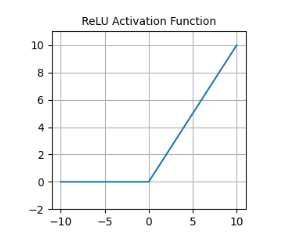

- often used as the default activation
- nn.fuinctional.relu()
- Zero for nrgative inputs - dying neurons

#### ELU Activation Function
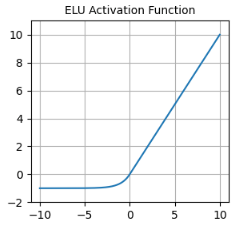

- nn.functional.elu()
- non-zero gradients for negative values - helps against dying neurons
- Average output around zero - helps against vanishing gradients

#### Batch Normalization

- after training for a while, the weights might change abnormal to value from 0.2 to 50, later it
could become 0.001 which cause vanishing graditents so
- After a layer we normalize the layer's outputs by:
      - subracting the mean
      - Dividing by the standard deviation
- BatchNorm performs approximately:

- If we always force the output to have mean = 0 and standard deviation = 1, we might actually restrict the neural network too much.

- So, BatchNorm learns two additional parameters:
  - **Scale ($\gamma$)**
  - **Shift ($\beta$)**

- The final BatchNorm operation is:

  $$y = \gamma\hat{x} + \beta$$

- Therefore, the complete BatchNorm process is:

  1. **Calculate the batch mean:**
     
     $$\mu_B = \frac{1}{m}\sum_{i=1}^{m}x_i$$

  2. **Calculate the batch variance:**
     
     $$\sigma_B^2 = \frac{1}{m}\sum_{i=1}^{m}(x_i-\mu_B)^2$$

  3. **Normalize the input:**
     
     $$\hat{x} = \frac{x-\mu_B}{\sqrt{\sigma_B^2+\epsilon}}$$

  4. **Scale and shift the normalized value:**
     
     $$y = \gamma\hat{x}+\beta$$

$$
y = \gamma
\left(
\frac{x-\mu_B}
{\sqrt{\sigma_B^2+\epsilon}}
\right)
+\beta
$$

In [ ]:
# simple model writing withBatch Normalization
import torch.nn as nn
import torch.nn.functional as F
import torch.nn.init as init

class ANN1(nn.Module):
    def __init__(self):
        super().__init__()
        # Input layer
        self.fc1 = nn.Linear(2, 4)
        # Batch Normalization
        self.bn1 = nn.BatchNorm1d(4)
        # Hidden Layer
        self.fc2 = nn.Linear(4, 2)
        # Output Layer
        self.fc3 = nn.Linear(2, 1)
        
    def forward(self, x):
        x = self.fc1(x)
        x = self.bn1(x)
        x = F.relu(x)
    
        x = F.relu(self.fc2(x))
        
        x = F.sigmoid(self.fc3(x))

        return x